In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

In [2]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIV_raw.mtx').T

In [3]:
adata

AnnData object with n_obs × n_vars = 11008 × 26705

In [4]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIV_raw_cellnames.csv")["x"]

In [5]:
cellnames 

0        AAACCCAGTAGACGTG-1_1
1        AAACCCATCACGATCA-1_1
2        AAACGAACATCCAACA-1_1
3        AAACGAAGTGTTGACT-1_1
4        AAACGAAGTTTGGAGG-1_1
                 ...         
11003    TTTGGTTTCTATACGG-1_3
11004    TTTGTTGCAGATCCTA-1_3
11005    TTTGTTGCATTGAGCT-1_3
11006    TTTGTTGTCACGTAGT-1_3
11007    TTTGTTGTCATCACCC-1_3
Name: x, Length: 11008, dtype: object

In [7]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIV_raw_genenames.csv")["x"]

In [8]:
adata.obs_names = cellnames
adata.var_names = genenames

In [9]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageIV_metatable.csv')

In [10]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCAGTAGACGTG-1_1,Stage_IV_Exp3,AAACCCAGTAGACGTG,NaN,NaN
AAACCCATCACGATCA-1_1,Stage_IV_Exp3,AAACCCATCACGATCA,CTGTCTGACAGTGTGTGTGTCTCTCTGTCTCA-1-3,IV-OTX2+VLMCs
AAACGAACATCCAACA-1_1,Stage_IV_Exp3,AAACGAACATCCAACA,GTGACTCAGTGACACACAGAGTGTGTGTGTCA-1-3,IV-OTX2+VLMCs
AAACGAAGTGTTGACT-1_1,Stage_IV_Exp3,AAACGAAGTGTTGACT,CTGTGTCAGTGTCTGTGTGTCACTCTGTGAGTCT-1-3,IV-OTX2+VLMCs
AAACGAAGTTTGGAGG-1_1,Stage_IV_Exp3,AAACGAAGTTTGGAGG,GTGTGAGAGTGTGTGTGTCTCTGTCTGTGTGAGTCTCT-1-3,IV-hGluts
...,...,...,...,...
TTTGGTTTCTATACGG-1_3,Stage_IV_Rep3_Exp3,TTTGGTTTCTATACGG,NaN,NaN
TTTGTTGCAGATCCTA-1_3,Stage_IV_Rep3_Exp3,TTTGTTGCAGATCCTA,NaN,NaN
TTTGTTGCATTGAGCT-1_3,Stage_IV_Rep3_Exp3,TTTGTTGCATTGAGCT,NaN,NaN


In [11]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [12]:
adata.obs["barcode"]

x
AAACCCAGTAGACGTG-1_1                                           NaN
AAACCCATCACGATCA-1_1          CTGTCTGACAGTGTGTGTGTCTCTCTGTCTCA-1-3
AAACGAACATCCAACA-1_1          GTGACTCAGTGACACACAGAGTGTGTGTGTCA-1-3
AAACGAAGTGTTGACT-1_1        CTGTGTCAGTGTCTGTGTGTCACTCTGTGAGTCT-1-3
AAACGAAGTTTGGAGG-1_1    GTGTGAGAGTGTGTGTGTCTCTGTCTGTGTGAGTCTCT-1-3
                                           ...                    
TTTGGTTTCTATACGG-1_3                                           NaN
TTTGTTGCAGATCCTA-1_3                                           NaN
TTTGTTGCATTGAGCT-1_3                                           NaN
TTTGTTGTCACGTAGT-1_3                                           NaN
TTTGTTGTCATCACCC-1_3                                           NaN
Name: barcode, Length: 11008, dtype: object

In [13]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [14]:
adata_no_nan

View of AnnData object with n_obs × n_vars = 3191 × 26705
    obs: 'barcode'

In [15]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

/tmp/ipykernel_2329916/2707677046.py:4: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")


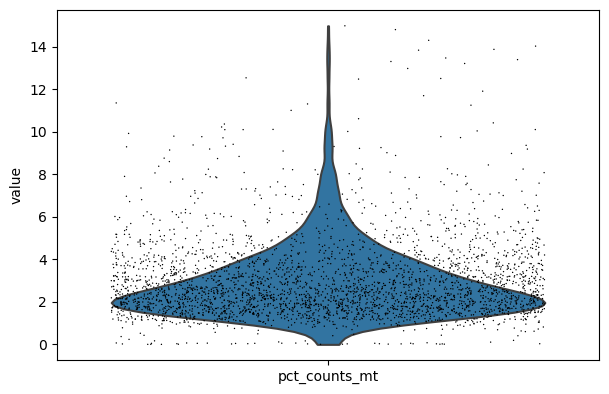

In [16]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [17]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

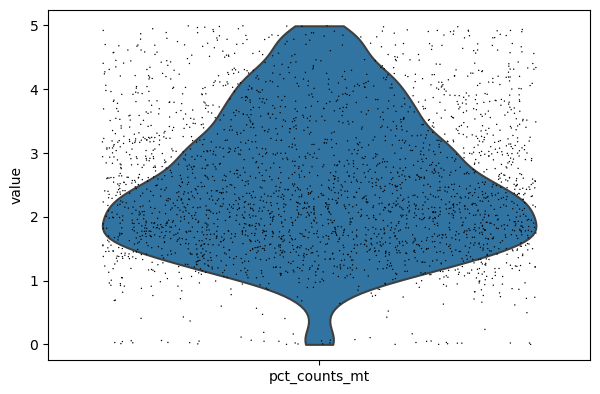

In [18]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [19]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [20]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
#sc.pp.log1p(adata_no_nan)


adata_filtered = adata_no_nan

In [21]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [22]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [23]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [24]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [25]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [26]:
df

x,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,RP11-54O7.16,...,RP11-21B23.1,RP11-558A11.1,MIR2117HG,RP11-756J15.3,LINC01440,FPR3,CECR7,CTA-992D9.6,barcode,barcode_cont
0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTCTGACAGTGTGTGTGTCTCTCTGTCTCA-1-3,0
1,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGACTCAGTGACACACAGAGTGTGTGTGTCA-1-3,1
2,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTGTCAGTGTCTGTGTGTCACTCTGTGAGTCT-1-3,2
3,0.0,0.000000,0.580956,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTGAGAGTGTGTGTGTCTCTGTCTGTGTGAGTCTCT-1-3,3
4,0.0,1.004218,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GAGTCTGTCTCACTCTGTGACTGTCTGAGTGT-1-3,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2859,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGTGACTCTCTGTCTGTCTGTCACTGTGT-2-3,2000
2860,0.0,0.000000,2.733983,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTCTGTGTCTGTGTCAGTCAGTGTCTGTCT-2-3,2001
2861,0.0,0.376251,0.376251,0.0,0.0,0.0,0.0,0.0,0.0,0.376251,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTCTCAGAGTCTCAGTCTGTGTGTCAGACT-2-3,2002
2862,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTGAGTGTGTGTGTGTGACTCTGTGTGTGT-2-3,1184


In [27]:
df = df.drop("barcode", axis=1)

In [28]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_nolog/you_stage4_barcode_all_genes_nolog.pkl')
